In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

from cyclical_MCMC import cyclical_MCMC, plot_distributions, plot_Vts, plot_VY

# Load data

In [3]:
# load data
SP500_df = pd.read_csv('SP500.csv')

# take log-diffs and drop nans
SP500_df['log_prices'] = SP500_df['SP500'].apply(lambda x: np.log(x))
SP500_df['log_returns'] = SP500_df['log_prices'].diff()

# set index
SP500_df['observation_date'] = pd.DatetimeIndex(SP500_df['observation_date'])
SP500_df = SP500_df.set_index('observation_date')

# print dates
print(f'Data from {SP500_df.index[0]} to {SP500_df.index[-1]}')

# drop nans -> inspect which is nans
SP500_df = SP500_df.dropna(subset=['log_prices'])

Data from 2016-09-19 00:00:00 to 2026-09-17 00:00:00


# Priors and guesses

In [4]:
Delta = 1/252
T = len(SP500_df['log_prices'])
Y = SP500_df['log_prices'].to_numpy()
theta_init = SP500_df['log_returns'].var()/Delta

init_guess_Theta = {
    'mu' : 0.00,
    'kappa' : 1.0,
    'kappatheta' : theta_init,
    'sigma_sq_V' : 0.001,
    'rho' : -0.5,
}

init_guess_V = np.ones(T)*theta_init

priors = {

    # mu
    'mu_mu' : 0.0,
    'sigma_sq_mu' : 1.0,

    # kappa
    'mu_kappa' : 0.0,
    'sigma_sq_kappa' : 1.0,

    # kappatheta
    'mu_kappatheta' : 0.0,
    'sigma_sq_kappatheta' : 1.0,

    # sigma_V
    'alpha_sigma_sq_V' : 2.5,
    'beta_sigma_sq_V' : 0.1,

    # rho
    'rho_low' : -1,
    'rho_high' : 1
    
}

# Sample

In [5]:
G = 100_000

def allocate_draws(G, T):
    draws = {
        'mu_draws' : np.zeros((G,)) + np.nan,
        'kappa_draws' : np.zeros((G,)) + np.nan,
        'kappatheta_draws' : np.zeros((G,)) + np.nan,
        'sigma_sq_V_draws' : np.zeros((G,)) + np.nan,
        'rho_draws' : np.zeros((G,)) + np.nan,
        'V_draws' : np.zeros((T,G)) + np.nan
    }
    return draws

def allocate_accepts(G, T):
    accepts = {
        'sigma_sq_V' : np.zeros((G,)) + np.nan,
        'rho' : np.zeros((G,)) + np.nan,
        'V' : np.zeros((T,G)) + np.nan
    }
    return accepts

draws = allocate_draws(G, T)
accepts = allocate_accepts(G, T)

In [6]:
cyclical_MCMC(priors, init_guess_Theta, init_guess_V, Y, draws, accepts, G, Delta)

g = 0


/Applications/anaconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Applications/anaconda3/lib/python3.12/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


g = 10
g = 20
g = 30
g = 40
g = 50
g = 60
g = 70
g = 80
g = 90
g = 100
g = 110
g = 120
g = 130
g = 140
g = 150
g = 160
g = 170
g = 180
g = 190
g = 200
g = 210
g = 220
g = 230
g = 240
g = 250
g = 260
g = 270
g = 280
g = 290
g = 300
g = 310
g = 320
g = 330
g = 340
g = 350
g = 360
g = 370
g = 380
g = 390
g = 400
g = 410
g = 420
g = 430
g = 440
g = 450
g = 460
g = 470
g = 480
g = 490
g = 500
g = 510
g = 520
g = 530
g = 540
g = 550
g = 560
g = 570
g = 580
g = 590
g = 600
g = 610
g = 620
g = 630
g = 640
g = 650
g = 660
g = 670
g = 680
g = 690
g = 700
g = 710
g = 720
g = 730
g = 740
g = 750
g = 760
g = 770
g = 780
g = 790
g = 800
g = 810
g = 820
g = 830
g = 840
g = 850
g = 860
g = 870
g = 880
g = 890
g = 900
g = 910
g = 920
g = 930
g = 940
g = 950
g = 960
g = 970
g = 980
g = 990
g = 1000
g = 1010
g = 1020
g = 1030
g = 1040
g = 1050
g = 1060
g = 1070
g = 1080
g = 1090
g = 1100
g = 1110
g = 1120
g = 1130
g = 1140
g = 1150
g = 1160
g = 1170
g = 1180
g = 1190
g = 1200
g = 1210
g = 1220
g = 1230
g

KeyboardInterrupt: 

# Marginal Distributions

In [7]:
burnin = 100

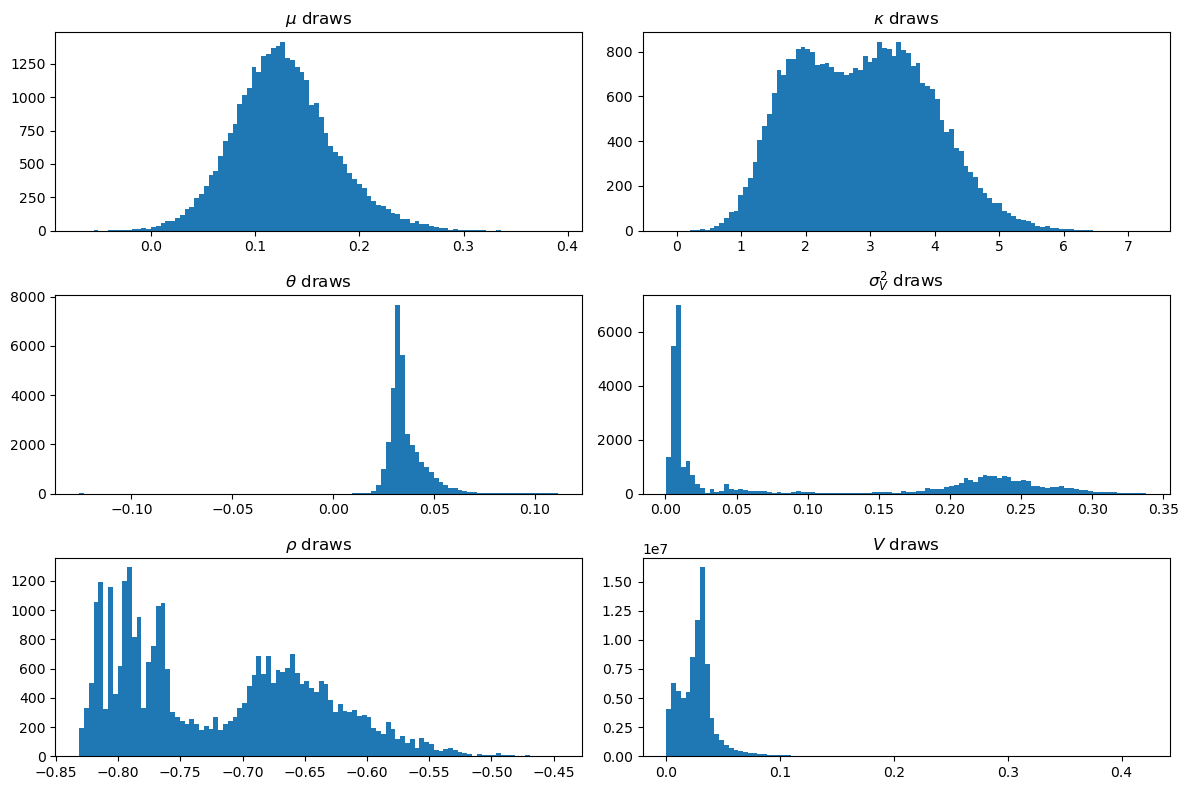

In [8]:
plot_distributions(draws, G, burnin=burnin)

# Acceptance rates

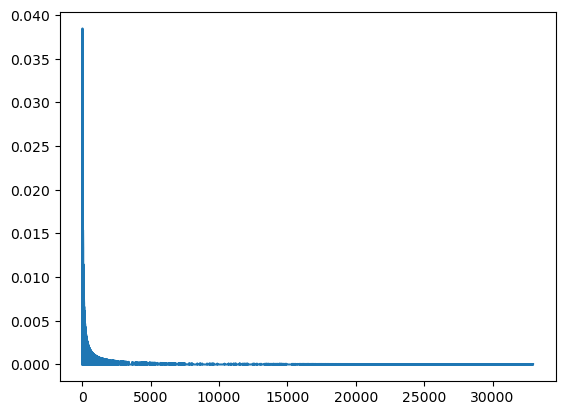

In [9]:
cum_acceptrate = accepts['rho'][~np.isnan(accepts['rho'])] / np.arange(1,1+np.sum(~np.isnan(accepts['rho'])))

plt.plot(cum_acceptrate)

# Marginal V distributions

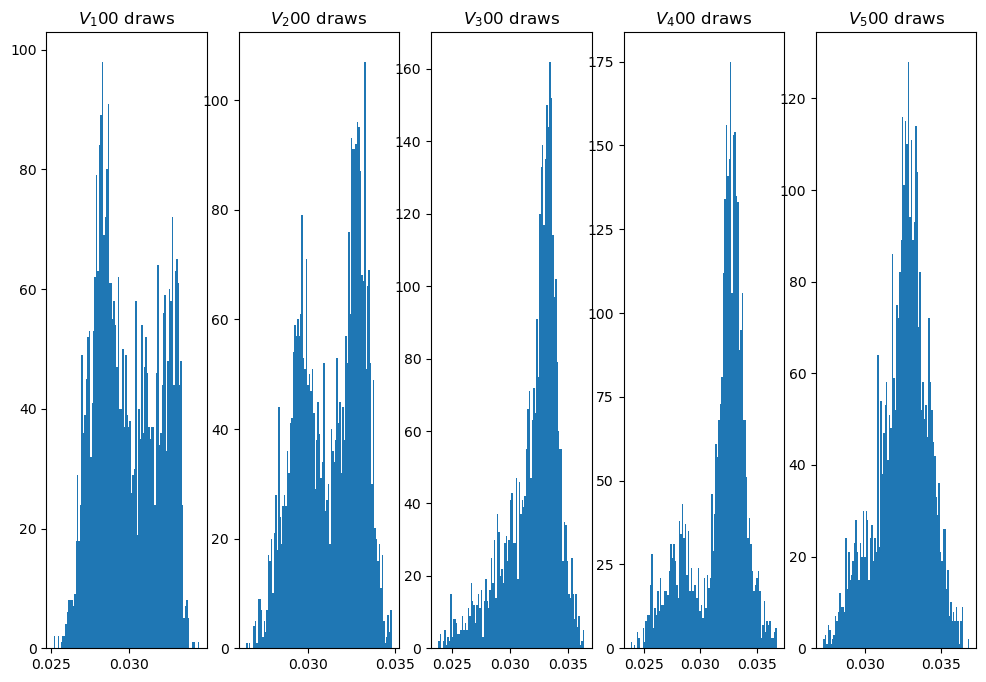

In [ ]:
plot_Vts(draws, [100, 200, 300, 400, 500], burnin=burnin)

# Series of $dY_t$ and $\mathbb{E}[V_t]$

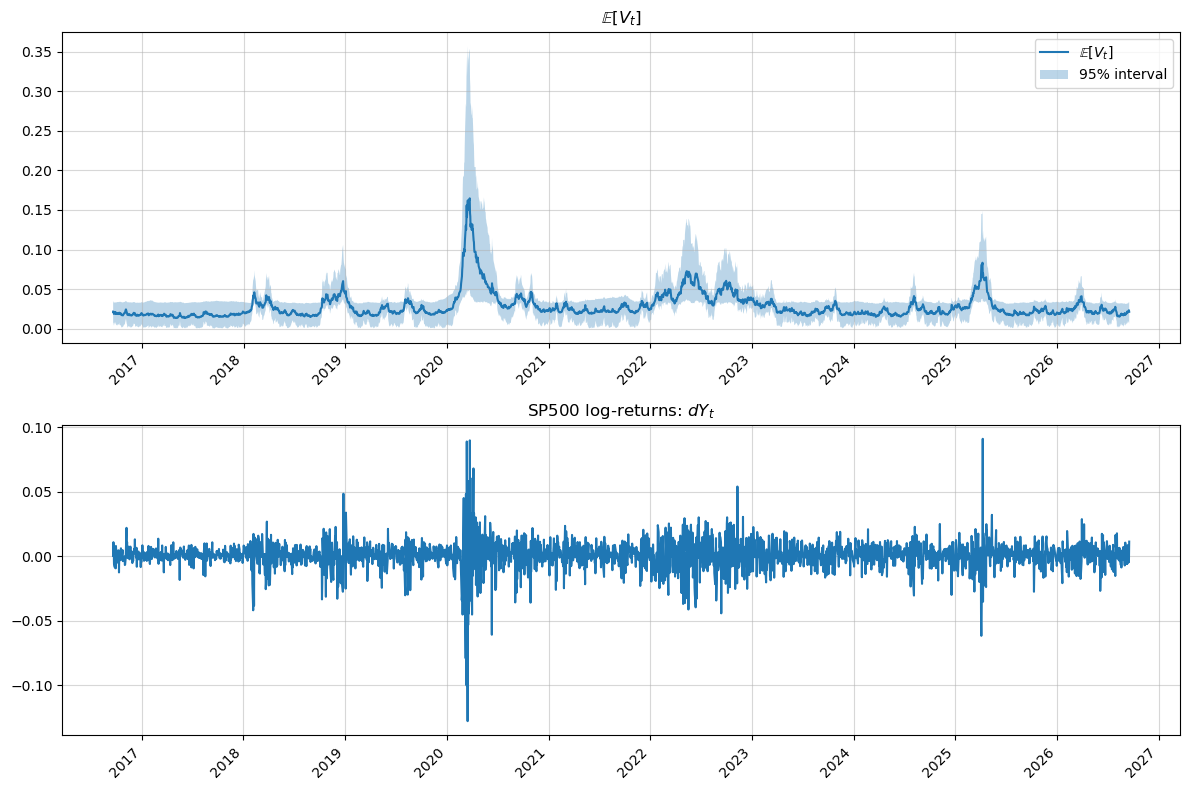

In [10]:
plot_VY(draws, Y, SP500_df.index, burnin=burnin)